In [27]:
import json
import os

# Path to your kaggle.json
kaggle_json_path = r"C:\Ameya\.kaggle\kaggle.json"

# Load credentials
with open(kaggle_json_path) as f:
    creds = json.load(f)

# Set environment variables
os.environ['KAGGLE_USERNAME'] = creds['username']
os.environ['KAGGLE_KEY'] = creds['key']

print("Kaggle credentials loaded successfully!")
!kaggle datasets download -d navoneel/brain-mri-images-for-brain-tumor-detection -p ./dataset --unzip


# List files in the dataset folder
print(os.listdir('./dataset'))



Kaggle credentials loaded successfully!
Dataset URL: https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection
License(s): copyright-authors

['brain_tumor_dataset', 'no', 'yes']



  0%|          | 0.00/15.1M [00:00<?, ?B/s]
100%|##########| 15.1M/15.1M [00:00<00:00, 942MB/s]


In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("navoneel/brain-mri-images-for-brain-tumor-detection")

print("Path to dataset files:", path)

C:\Users\Shweta Ganesh\Desktop\fer\mlenv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Shweta Ganesh\.cache\kagglehub\datasets\navoneel\brain-mri-images-for-brain-tumor-detection\versions\1


In [1]:

DATASET_PATH = path  

print("Classes found in dataset folder:", os.listdir(DATASET_PATH))
print("Number of 'yes' images:", len(os.listdir(os.path.join(DATASET_PATH, 'yes'))))
print("Number of 'no' images:", len(os.listdir(os.path.join(DATASET_PATH, 'no'))))

print("\nTraining images (VGG):", train_vgg.samples)
print("Validation images (VGG):", val_vgg.samples)
print("Test images (VGG):", test_vgg.samples)
pribt("total images:", train_vgg.samples + test_vgg.samples + val_vgg.samples)

Classes found in dataset folder: ['brain_tumor_dataset', 'no', 'yes']
Number of 'yes' images: 1025
Number of 'no' images: 1028
total images: 2053


In [3]:

import os
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet import preprocess_input as resnet_preprocess
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.models import load_model


RANDOM_SEED = 123
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 1  # binary classification
EPOCHS = 20



# Use validation_split to split within yes/no subfolders
train_val_datagen_vgg = ImageDataGenerator(
    preprocessing_function=vgg_preprocess,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    brightness_range=[0.5, 1.5],
    horizontal_flip=True,
    vertical_flip=True,
    validation_split=0.2  # 80% train, 20% val
)

base_datagen_vgg = ImageDataGenerator(
    preprocessing_function=vgg_preprocess,
    validation_split=0.1  # 10% test split
)

train_val_datagen_resnet = ImageDataGenerator(
    preprocessing_function=resnet_preprocess,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    brightness_range=[0.5, 1.5],
    horizontal_flip=True,
    vertical_flip=True,
    validation_split=0.2
)

base_datagen_resnet = ImageDataGenerator(
    preprocessing_function=resnet_preprocess,
    validation_split=0.1
)

# -----------------------------
# VGG16 SPLITS
# -----------------------------
train_vgg = train_val_datagen_vgg.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['no', 'yes'],     # ✅ explicitly use only these folders
    subset='training',
    seed=RANDOM_SEED
)

val_vgg = train_val_datagen_vgg.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['no', 'yes'],
    subset='validation',
    seed=RANDOM_SEED
)

test_vgg = base_datagen_vgg.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['no', 'yes'],
    subset='validation',
    seed=RANDOM_SEED,
    shuffle=False
)

# -----------------------------
# RESNET50 SPLITS
# -----------------------------
train_resnet = train_val_datagen_resnet.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['no', 'yes'],
    subset='training',
    seed=RANDOM_SEED
)

val_resnet = train_val_datagen_resnet.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['no', 'yes'],
    subset='validation',
    seed=RANDOM_SEED
)

test_resnet = base_datagen_resnet.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['no', 'yes'],
    subset='validation',
    seed=RANDOM_SEED,
    shuffle=False
)


# -----------------------------
# MODEL BUILDERS
# -----------------------------
def build_vgg16(input_shape=(224,224,3)):
    base = VGG16(weights='imagenet', include_top=False, input_shape=input_shape)
    base.trainable = False
    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation='sigmoid')
    ])
    model.compile(loss='binary_crossentropy',
                  optimizer=RMSprop(learning_rate=1e-4),
                  metrics=['accuracy'])
    return model

def build_resnet50(input_shape=(224,224,3)):
    base = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    base.trainable = False
    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='sigmoid')(x)
    model = models.Model(inputs=base.input, outputs=outputs)
    model.compile(loss='binary_crossentropy',
                  optimizer=RMSprop(learning_rate=1e-4),
                  metrics=['accuracy'])
    return model


Classes found in dataset folder: ['brain_tumor_dataset', 'no', 'yes']
Number of 'yes' images: 155
Number of 'no' images: 98
Found 203 images belonging to 2 classes.
Found 50 images belonging to 2 classes.
Found 24 images belonging to 2 classes.
Found 203 images belonging to 2 classes.
Found 50 images belonging to 2 classes.
Found 24 images belonging to 2 classes.

Training images (VGG): 203
Validation images (VGG): 50
Test images (VGG): 24


In [9]:
es = EarlyStopping(monitor='val_accuracy', mode='max', patience=5, restore_best_weights=True)
checkpoint_vgg = ModelCheckpoint('vgg16_best.h5', save_best_only=True, monitor='val_accuracy', mode='max')
checkpoint_resnet = ModelCheckpoint('resnet50_best.h5', save_best_only=True, monitor='val_accuracy', mode='max')

# -----------------------------
# TRAIN MODELS
# -----------------------------
vgg_model = build_vgg16()
print("\nTraining VGG16...\n")
history_vgg = vgg_model.fit(
    train_vgg,
    validation_data=val_vgg,
    epochs=EPOCHS,
    callbacks=[checkpoint_vgg],
    verbose=1
)


# -----------------------------
# EVALUATE ON TEST SET
# -----------------------------
print("\nEvaluating VGG16 on Test Set...")
vgg_test_loss, vgg_test_acc = vgg_model.evaluate(test_vgg)
print(f"VGG16 Test Accuracy: {vgg_test_acc:.4f}")

# from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
# import matplotlib.pyplot as plt
# import seaborn as sns
# import numpy as np

# # 1. Get class names
# class_indices = train_vgg.class_indices
# classes = list(class_indices.keys())
# print("Classes:", classes)

# # 2. Predict on validation set
# val_steps = val_vgg.samples // val_vgg.batch_size
# y_pred_probs = vgg_model.predict(val_vgg, steps=val_steps+1)
# y_pred = np.argmax(y_pred_probs, axis=1)

# # 3. True labels
# y_true = val_vgg.classes[:len(y_pred)]  # match length

# # 4. Confusion matrix
# cm = confusion_matrix(y_true, y_pred)
# plt.figure(figsize=(6,5))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
# plt.xlabel("Predicted")
# plt.ylabel("Actual")
# plt.title("Confusion Matrix")
# plt.show()

# # 5. Classification report
# report = classification_report(y_true, y_pred, target_names=classes)
# print("Classification Report:\n", report)

# # 6. Other metrics
# accuracy = accuracy_score(y_true, y_pred)
# precision_macro = precision_score(y_true, y_pred, average='macro')
# recall_macro = recall_score(y_true, y_pred, average='macro')
# f1_macro = f1_score(y_true, y_pred, average='macro')

# precision_micro = precision_score(y_true, y_pred, average='micro')
# recall_micro = recall_score(y_true, y_pred, average='micro')
# f1_micro = f1_score(y_true, y_pred, average='micro')

# print(f"Accuracy: {accuracy:.4f}")
# print(f"Precision (Macro): {precision_macro:.4f}, Recall (Macro): {recall_macro:.4f}, F1 (Macro): {f1_macro:.4f}")
# print(f"Precision (Micro): {precision_micro:.4f}, Recall (Micro): {recall_micro:.4f}, F1 (Micro): {f1_micro:.4f}")




Training VGG16...

Epoch 1/20
7/7 [==============================] - 36s 5s/step - loss: 2.5603 - accuracy: 0.5074 - val_loss: 1.5528 - val_accuracy: 0.5400
Epoch 2/20


C:\Users\Shweta Ganesh\Desktop\fer\mlenv\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


7/7 [==============================] - 32s 4s/step - loss: 2.1739 - accuracy: 0.5419 - val_loss: 1.1701 - val_accuracy: 0.5800
Epoch 3/20
7/7 [==============================] - 31s 4s/step - loss: 2.4649 - accuracy: 0.5419 - val_loss: 1.2132 - val_accuracy: 0.6000
Epoch 4/20
7/7 [==============================] - 32s 5s/step - loss: 2.0963 - accuracy: 0.5222 - val_loss: 0.9253 - val_accuracy: 0.6800
Epoch 5/20
7/7 [==============================] - 32s 5s/step - loss: 2.3540 - accuracy: 0.5123 - val_loss: 1.2583 - val_accuracy: 0.6200
Epoch 6/20
7/7 [==============================] - 30s 4s/step - loss: 2.1276 - accuracy: 0.5862 - val_loss: 1.0461 - val_accuracy: 0.6000
Epoch 7/20
7/7 [==============================] - 30s 4s/step - loss: 2.0198 - accuracy: 0.5665 - val_loss: 1.1109 - val_accuracy: 0.6000
Epoch 8/20
7/7 [==============================] - 30s 4s/step - loss: 2.3386 - accuracy: 0.5764 - val_loss: 1.0159 - val_accuracy: 0.6600
Epoch 9/20
7/7 [=============================

In [15]:
resnet_model = build_resnet50()
print("\nTraining ResNet50...\n")
history_resnet = resnet_model.fit(
    train_resnet,
    validation_data=val_resnet,
    epochs=EPOCHS,
    callbacks=[es, checkpoint_resnet],
    verbose=1
)

print("\nEvaluating ResNet50 on Test Set...")
resnet_test_loss, resnet_test_acc = resnet_model.evaluate(test_resnet)
print(f"ResNet50 Test Accuracy: {resnet_test_acc:.4f}")




Training ResNet50...

Epoch 1/20
7/7 [==============================] - 22s 3s/step - loss: 1.3090 - accuracy: 0.3892 - val_loss: 0.9633 - val_accuracy: 0.4600
Epoch 2/20
7/7 [==============================] - 16s 2s/step - loss: 1.1005 - accuracy: 0.4286 - val_loss: 0.8544 - val_accuracy: 0.4800
Epoch 3/20
7/7 [==============================] - 16s 2s/step - loss: 1.0988 - accuracy: 0.4433 - val_loss: 0.7796 - val_accuracy: 0.4200
Epoch 4/20
7/7 [==============================] - 16s 2s/step - loss: 1.0209 - accuracy: 0.4778 - val_loss: 0.7119 - val_accuracy: 0.6000
Epoch 5/20
7/7 [==============================] - 15s 2s/step - loss: 0.9466 - accuracy: 0.4729 - val_loss: 0.6799 - val_accuracy: 0.6000
Epoch 6/20
7/7 [==============================] - 16s 2s/step - loss: 0.8501 - accuracy: 0.5567 - val_loss: 0.6695 - val_accuracy: 0.6200
Epoch 7/20
7/7 [==============================] - 15s 2s/step - loss: 0.9385 - accuracy: 0.5517 - val_loss: 0.6719 - val_accuracy: 0.6200
Epoch 8/20


In [27]:
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing import image
import tensorflow as tf

# Input
inputs = layers.Input(shape=(224, 224, 3), name="img")

# VGG16
vgg = VGG16(input_tensor=inputs, weights='imagenet', include_top=False)
for layer in vgg.layers:
    layer.trainable = False
vgg_out = layers.GlobalAveragePooling2D()(vgg.output)

# ResNet50
resnet = ResNet50(input_tensor=inputs, weights='imagenet', include_top=False)
for layer in resnet.layers:
    layer.trainable = False
resnet_out = layers.GlobalAveragePooling2D()(resnet.output)

# Merge
merged = layers.Concatenate()([vgg_out, resnet_out])
x = layers.Dense(256, activation="relu")(merged)
x = layers.Dropout(0.5)(x)  # Optional dropout
prediction = layers.Dense(2, activation='softmax')(x)

# Model
model = Model(inputs=inputs, outputs=prediction)
model.compile(loss="categorical_crossentropy", optimizer='adam', metrics=['accuracy'])
model.summary()

# Data generators
train_datagen = image.ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = image.ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    classes=['no', 'yes']
)
validation_generator = test_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    classes=['no', 'yes']
)

#


Model: "model_7"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 img (InputLayer)            [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 230, 230, 3)          0         ['img[0][0]']                 
                                                                                                  
 conv1_conv (Conv2D)         (None, 112, 112, 64)         9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 112, 112, 64)         256       ['conv1_conv[0][0]']          
 on)                                                                                        

In [29]:
 #Training
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    epochs=20,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // validation_generator.batch_size
)

Epoch 1/20
7/7 [==============================] - 77s 11s/step - loss: 0.8092 - accuracy: 0.5973 - val_loss: 0.6082 - val_accuracy: 0.6205
Epoch 2/20
7/7 [==============================] - 68s 10s/step - loss: 0.7191 - accuracy: 0.6063 - val_loss: 0.5579 - val_accuracy: 0.6786
Epoch 3/20
7/7 [==============================] - 68s 10s/step - loss: 0.6741 - accuracy: 0.6652 - val_loss: 0.5515 - val_accuracy: 0.7679
Epoch 4/20
7/7 [==============================] - 69s 11s/step - loss: 0.6555 - accuracy: 0.6425 - val_loss: 0.4995 - val_accuracy: 0.7723
Epoch 5/20
7/7 [==============================] - 70s 11s/step - loss: 0.5937 - accuracy: 0.7014 - val_loss: 0.5141 - val_accuracy: 0.7723
Epoch 6/20
7/7 [==============================] - 69s 10s/step - loss: 0.5399 - accuracy: 0.7376 - val_loss: 0.5166 - val_accuracy: 0.7679
Epoch 7/20
7/7 [==============================] - 67s 10s/step - loss: 0.5370 - accuracy: 0.7557 - val_loss: 0.5253 - val_accuracy: 0.7589
Epoch 8/20
7/7 [===========

In [35]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import numpy as np
validation_generator = test_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    classes=['no', 'yes'],
    shuffle=False
)
# 1. Get class names
classes = list(train_generator.class_indices.keys())

# 2. Predict on validation set
val_steps = validation_generator.samples // validation_generator.batch_size
y_pred_probs = model.predict(validation_generator, steps=val_steps+1)
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. True labels
y_true = validation_generator.classes[:len(y_pred)]

# 4. Classification report dictionary
report_dict = classification_report(y_true, y_pred, target_names=classes, output_dict=True)

# 5. Create table
metrics_table = pd.DataFrame(report_dict).transpose()

# 6. Add overall accuracy row manually
metrics_table.loc['overall_accuracy'] = [accuracy_score(y_true, y_pred), np.nan, np.nan, np.nan]

# 7. Round values for readability
metrics_table = metrics_table.round(4)

# 8. Display
print(metrics_table)


Found 253 images belonging to 2 classes.
8/8 [==============================] - 39s 5s/step
                  precision  recall  f1-score   support
no                   0.8452  0.7245    0.7802   98.0000
yes                  0.8402  0.9161    0.8765  155.0000
accuracy             0.8419  0.8419    0.8419    0.8419
macro avg            0.8427  0.8203    0.8284  253.0000
weighted avg         0.8422  0.8419    0.8392  253.0000
overall_accuracy     0.8419     NaN       NaN       NaN


In [33]:
loss, acc = model.evaluate(validation_generator)
print("Validation accuracy (evaluate):", acc)


8/8 [==============================] - 40s 5s/step - loss: 0.3973 - accuracy: 0.8419
Validation accuracy (evaluate): 0.8418972492218018


Classes: ['no', 'yes']
8/8 [==============================] - 40s 5s/step


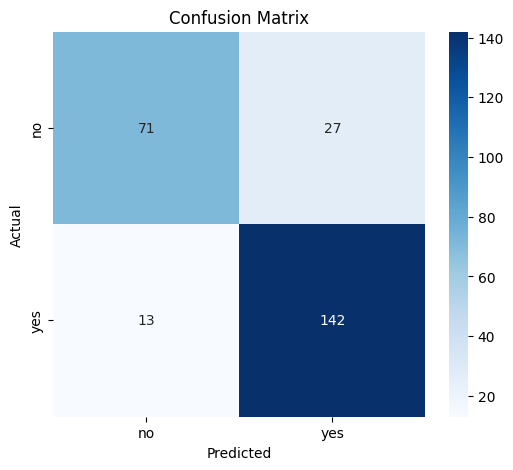

Classification Report:
               precision    recall  f1-score   support

          no       0.85      0.72      0.78        98
         yes       0.84      0.92      0.88       155

    accuracy                           0.84       253
   macro avg       0.84      0.82      0.83       253
weighted avg       0.84      0.84      0.84       253

Accuracy: 0.8419
Precision (Macro): 0.8427, Recall (Macro): 0.8203, F1 (Macro): 0.8284
Precision (Micro): 0.8419, Recall (Micro): 0.8419, F1 (Micro): 0.8419


In [37]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Get class names
class_indices = train_generator.class_indices
classes = list(class_indices.keys())
print("Classes:", classes)

# 2. Predict on validation set
val_steps = validation_generator.samples // validation_generator.batch_size
y_pred_probs = model.predict(validation_generator, steps=val_steps+1)
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. True labels
y_true = validation_generator.classes[:len(y_pred)]  # match length

# 4. Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# 5. Classification report
report = classification_report(y_true, y_pred, target_names=classes)
print("Classification Report:\n", report)

# 6. Other metrics
accuracy = accuracy_score(y_true, y_pred)
precision_macro = precision_score(y_true, y_pred, average='macro')
recall_macro = recall_score(y_true, y_pred, average='macro')
f1_macro = f1_score(y_true, y_pred, average='macro')

precision_micro = precision_score(y_true, y_pred, average='micro')
recall_micro = recall_score(y_true, y_pred, average='micro')
f1_micro = f1_score(y_true, y_pred, average='micro')

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (Macro): {precision_macro:.4f}, Recall (Macro): {recall_macro:.4f}, F1 (Macro): {f1_macro:.4f}")
print(f"Precision (Micro): {precision_micro:.4f}, Recall (Micro): {recall_micro:.4f}, F1 (Micro): {f1_micro:.4f}")
